In [ ]:
import os

# Select "cuda" before the first PyRITE import, then restart the kernel.
os.environ.setdefault("PYRITE_MC_BACKEND", "cpu")
import marimo as mo  # noqa: F401
import matplotlib.pyplot as plt
import numpy as np

import pyrite

with mo.status.spinner(title="Preparing PyRITE reference tables"):
    _ = pyrite.fetch_tables()  # Installed pins are reused without downloading again.

tables_ready = True

# Parameter sweeps

[![Open in Molab](https://marimo.io/molab-shield.svg)](https://molab.marimo.io/github/Quantum-Light-Matter-Cooperative-QLMC/pyrite/blob/main/docs/notebooks/08-parameter-sweeps.py)

Map the PXR/CBS yield as beam energy and HOPG thickness vary,
at a fixed 30° target tilt and 135° observation angle.

In [ ]:
from pyrite import simulate
from pyrite.beams import Beam, PointBunch, PointSpot
from pyrite.config import CxrReflections, FixedSampling, Numerics, Physics
from pyrite.detectors import Detector
from pyrite.geometry import Footprint, Slab
from pyrite.units import ureg

energies_keV = np.array([20.0, 25.0, 30.0, 35.0, 40.0])
thicknesses_nm = np.array([25.0, 50.0, 75.0, 100.0, 125.0])
band_eV = (600.0, 2_000.0)
detector = Detector(observation_angle=135 * ureg.degree)
physics = Physics(brem_source="none")
numerics = Numerics(
    sampling=FixedSampling(cxr_electrons=2_048, brem_electrons=2_048),
    cxr_reflections=CxrReflections(n_families=2),
)

In [ ]:
assert tables_ready
# Rows are thicknesses; columns are beam energies.
band_yield = np.zeros((len(thicknesses_nm), len(energies_keV)))
runs = []
with mo.status.progress_bar(
    total=len(thicknesses_nm) * len(energies_keV),
    title="Computing the parameter sweep",
    show_eta=True,
) as _progress:
    for _row, _thickness_nm in enumerate(thicknesses_nm):
        for _col, _energy_keV in enumerate(energies_keV):
            _result = simulate(
                Beam(
                    kinetic_energy=float(_energy_keV) * ureg.keV,
                    transverse=PointSpot(),
                    longitudinal=PointBunch(),
                ),
                Slab(
                    "hopg",
                    thickness=float(_thickness_nm) * ureg.nm,
                    tilt=30 * ureg.degree,
                    footprint=Footprint(width=5 * ureg.mm, height=5 * ureg.mm),
                ),
                detector,
                physics=physics,
                numerics=numerics,
            )
            _spectrum = _result.cxr.incoherent
            _grid = _spectrum.photon_energy_eV
            _lo, _hi = band_eV
            assert _grid[0] <= _lo < _hi <= _grid[-1]
            # Include interpolated band edges on each result's native grid.
            _nodes = np.r_[_lo, _grid[(_grid > _lo) & (_grid < _hi)], _hi]
            band_yield[_row, _col] = np.trapezoid(
                np.interp(_nodes, _grid, _spectrum.density), _nodes
            )
            runs.append(
                {
                    "energy_keV": float(_energy_keV),
                    "thickness_nm": float(_thickness_nm),
                    "seed": int(_result.case["seed"]),
                    "source_identity": _result.provenance["identity_digest"],
                }
            )
            _progress.update(subtitle=f"{_energy_keV:g} keV / {_thickness_nm:g} nm")
assert np.isfinite(band_yield).all() and np.all(band_yield >= 0)
sweep_result = _result
sweep_yield = band_yield.copy()

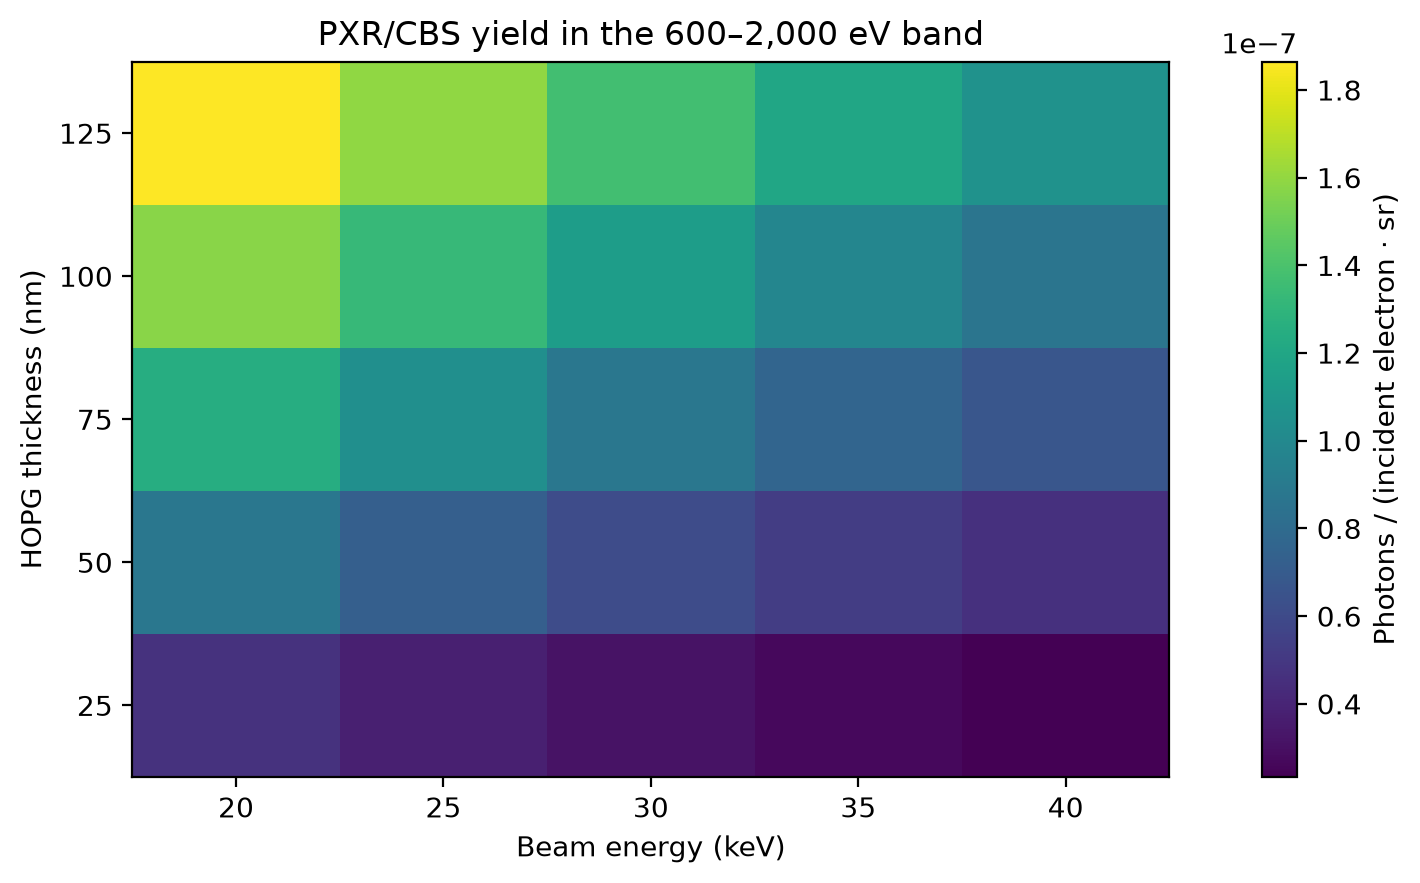

In [ ]:
fig_sweep, _ax = plt.subplots(figsize=(7, 4.3), layout="constrained")
_image = _ax.pcolormesh(energies_keV, thicknesses_nm, sweep_yield, shading="nearest")
_ax.set(
    xlabel="Beam energy (keV)",
    ylabel="HOPG thickness (nm)",
    title="PXR/CBS yield in the 600–2,000 eV band",
    xticks=energies_keV,
    yticks=thicknesses_nm,
)
fig_sweep.colorbar(_image, ax=_ax, label="Photons / (incident electron · sr)")
fig_sweep  # noqa: B018 - captured by marimo

Each tile integrates a source spectrum over the same photon-energy band;
it is a yield per incident electron and steradian, before detector response.
Here, yield grows with thickness and falls with beam energy.
All 25 runs use 2,048 sampled histories per population and seed 1.

Try shifting the energy band or replacing the thickness axis with target tilt.
Use [notebook 07](https://pyrite.readthedocs.io/en/latest/notebooks/designing/07-sampling-convergence-performance.html)
to choose a larger sampling budget for a selected region.

## Continue learning

Revisit [sampling](07-sampling-convergence-performance.ipynb) before comparing
nearby yields. For reusable campaign settings, use
[Campaign configuration](../../guides/sweep-profiles.md); the
[scene and sweep API](../../reference/python-api/core.md) defines parameter studies.
[Spectral observables](../../physics/radiation-physics/spectral-observables.md)
explain band-yield normalization. Review the selected models'
[validation status](../../validation/status-summary.md) before interpreting a response surface.

{download}`Download canonical Marimo notebook <../08-parameter-sweeps.py>`